# Notebook n°4 : Machine Learning non supervisé

### Problématique

Dans quelle mesure la structure du réseau TGV est-elle associée à la régularité des liaisons, et peut-on exploiter cette structure pour améliorer la prédiction des retards ?

## 1. Objectifs de ce notebook

Après avoir étudié la qualité des données dans le notebook 01 et réalisé l'analyse exploratoire dans le notebook 02, nous allons maintenant chercher à regrouper les liaisons TGV selon leurs caractéristiques, sans utiliser les catégories définies précédemment.

Notre objectif est de trouver des groupes de liaisons qui se ressemblent selon leur durée moyenne et les causes de retard, puis de voir si ces groupes sont différents de notre classification géographique (radiales, transversales et internationales).

Nous allons également comparer les taux de retard de ces groupes, sachant que le taux n'a pas été utilisé pour les créer. Cela pourrait nous permettre d'identifier des profils de liaisons associés à des niveaux de retard différents, qui pourraient ensuite être utiles pour la prédiction dans le notebook 05.

## 2. Méthode

Pour cela, nous allons d'abord regrouper les données mensuelles afin d'obtenir un profil pour chaque liaison. Ensuite, nous allons standardiser les variables pour les mettre à la même échelle.

Nous utiliserons la méthode du coude pour choisir le nombre de clusters, puis l'algorithme K-Means pour former les groupes et analyser leurs caractéristiques.

In [14]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [15]:
SEED = 42

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

DATA_PATH = project_root / "data" / "processed" / "sncf.parquet"
data = pd.read_parquet(DATA_PATH)

# On retire les observations signalées par les contrôles de qualité
colonnes_flags = [c for c in data.columns if c.startswith("flag_")]
a_un_flag = data[colonnes_flags].any(axis=1)
data = data.loc[~a_un_flag].drop(columns=colonnes_flags).copy()

# On affiche les dimensions des données conservées
print("Dimensions :", data.shape)


Dimensions : (12487, 26)


Nous chargeons le fichier parquet préparé par l'ETL de l'équipe, qui contient déjà les noms des colonnes normalisés et les indicateurs de qualité.

Nous retirons ensuite les 420 observations signalées par au moins un indicateur de qualité, ce qui nous laisse **12 487 observations mensuelles** pour la suite de l'analyse.

In [16]:

# On regroupe les deux sens d'une liaison dans une même paire de gares
data["paire"] = data.apply(
    lambda r: tuple(sorted([r["gare_depart"], r["gare_arrivee"]])),
    axis=1
)

# On définit les gares parisiennes pour classer les liaisons
paris_gares = ["PARIS LYON", "PARIS MONTPARNASSE", "PARIS NORD", "PARIS EST",
               "PARIS VAUGIRARD"]

# On classe les observations selon leur type de liaison
def type_liaison(ligne):
    if ligne["service"] == "International":
        return "international"
    if ligne["gare_depart"] in paris_gares:
        return "radiale depuis Paris"
    if ligne["gare_arrivee"] in paris_gares:
        return "radiale vers Paris"
    return "transversale"

data["type_liaison"] = data.apply(type_liaison, axis=1)

# On affiche le nombre de paires et la répartition des observations par type
print(f"Nombre de paires uniques : {data['paire'].nunique()}")
print("\nRépartition des types de liaisons :")
print(data["type_liaison"].value_counts())


Nombre de paires uniques : 65

Répartition des types de liaisons :
type_liaison
radiale vers Paris      4524
radiale depuis Paris    4523
transversale            1929
international           1511
Name: count, dtype: int64


On retrouve les 65 paires de gares du réseau, avec des observations réparties en quatre types selon notre classification géographique.

Chaque paire apparaît plusieurs fois dans les données, notamment sur différents mois. Nous allons donc regrouper ces observations pour obtenir un profil moyen par paire de gares.

In [17]:

# On crée un profil pour chaque paire de gares
# On utilise la durée moyenne et les pourcentages des causes de retard
colonnes_causes = [c for c in data.columns if c.startswith("prct_cause")]

features = ["duree_moyenne"] + colonnes_causes

# On regroupe les observations par paire et on calcule les moyennes
profils = (data.groupby("paire", observed=True)[features]
           .mean()
           .dropna())

# On affiche le nombre de profils et les caractéristiques utilisées
print(f"Nombre de paires avec un profil complet : {len(profils)}")
print(f"\nCaractéristiques utilisées : {features}")
profils.head()


Nombre de paires avec un profil complet : 65

Caractéristiques utilisées : ['duree_moyenne', 'prct_cause_externe', 'prct_cause_infra', 'prct_cause_gestion_trafic', 'prct_cause_materiel_roulant', 'prct_cause_gestion_gare', 'prct_cause_prise_en_charge_voyageurs']


,duree_moyenne,prct_cause_externe,prct_cause_infra,prct_cause_gestion_trafic,prct_cause_materiel_roulant,prct_cause_gestion_gare,prct_cause_prise_en_charge_voyageurs
paire,,,,,,,
"(AIX EN PROVENCE TGV, PARIS LYON)",185.389163,26.003514,19.302218,15.186504,22.167021,9.356550,7.984193
"(ANGERS SAINT LAUD, PARIS MONTPARNASSE)",93.725490,24.513686,24.343052,18.102709,15.964416,7.834069,9.242068
"(ANGOULEME, PARIS MONTPARNASSE)",127.941176,20.982807,24.073841,15.628148,16.971663,10.233973,12.109568
"(ANNECY, PARIS LYON)",226.262376,24.031359,22.129862,25.720767,18.877615,4.968923,2.786324
"(ARRAS, PARIS NORD)",50.127451,16.374538,20.915328,25.720541,17.704042,12.410265,6.875285


On retrouve bien les 65 paires de gares du réseau, sans en perdre à cause des valeurs manquantes.

Pour chaque paire, on utilise sept caractéristiques : la durée moyenne en minutes et les six pourcentages correspondant aux différentes causes de retard.

On remarque déjà des différences entre les liaisons. Par exemple, Paris Lyon <–> Aix-en-Provence est une liaison assez longue (environ 185 minutes), avec 26 % de causes externes. Or, Paris Nord <–> Arras est beaucoup plus courte (environ 50 minutes), avec 26 % de causes liées à la gestion du trafic.

Ces différences vont nous permettre de regrouper les liaisons qui présentent des profils similaires grâce au clustering.

In [18]:

# On met les caractéristiques à la même échelle
# La durée est en minutes et les causes de retard sont en pourcentage
# Sans normalisation, la durée aurait beaucoup plus de poids dans le clustering

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X = scaler.fit_transform(profils)

# On crée un DataFrame pour vérifier les résultats
X_scale = pd.DataFrame(X, index=profils.index, columns=profils.columns)

print("Après normalisation :")
print(X_scale.describe().round(2).loc[["mean", "std", "min", "max"]])


Après normalisation :
      duree_moyenne  prct_cause_externe  prct_cause_infra  \
mean           0.00               -0.00              0.00   
std            1.01                1.01              1.01   
min           -1.49               -1.91             -2.55   
max            3.04                2.34              2.42   

      prct_cause_gestion_trafic  prct_cause_materiel_roulant  \
mean                       0.00                         0.00   
std                        1.01                         1.01   
min                       -2.15                        -3.13   
max                        3.46                         4.02   

      prct_cause_gestion_gare  prct_cause_prise_en_charge_voyageurs  
mean                    -0.00                                 -0.00  
std                      1.01                                  1.01  
min                     -2.17                                 -2.20  
max                      2.21                                  1.86  


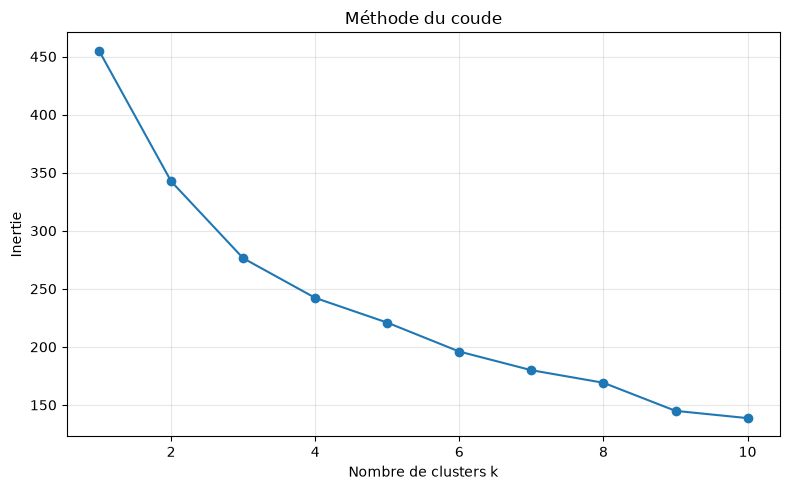

In [19]:

# On utilise la méthode du coude pour choisir le nombre de clusters
# On teste plusieurs valeurs de k et on compare les inerties
# Le but est de repérer à partir de quand l'inertie diminue moins rapidement

from sklearn.cluster import KMeans

inerties = []
valeurs_k = range(1, 11)

for k in valeurs_k:
    modele = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    modele.fit(X)
    inerties.append(modele.inertia_)

# On affiche la courbe
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(valeurs_k, inerties, marker="o")
ax.set_xlabel("Nombre de clusters k")
ax.set_ylabel("Inertie")
ax.set_title("Méthode du coude")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


On remarque que l'inertie diminue fortement lorsque le nombre de clusters augmente au début, puis que la baisse devient moins importante à partir de 3 ou 4 clusters.

Nous choisissons donc de retenir 4 clusters pour la suite de l'analyse, afin de distinguer plusieurs profils de liaisons sans créer trop de groupes. Ce choix nous permettra également de comparer les clusters obtenus avec les quatre catégories de notre typologie géographique, présentées dans la section 5 du notebook 02.

In [20]:
# clustering K-Means avec k=4
# chaque liaison recoit un numero de cluster entre 0 et 3

modele = KMeans(n_clusters=4, random_state=SEED, n_init=10)
profils["cluster"] = modele.fit_predict(X)

print("Repartition des liaisons par cluster :")
print(profils["cluster"].value_counts().sort_index())

Repartition des liaisons par cluster :
cluster
0    25
1    19
2     5
3    16
Name: count, dtype: int64


Le clustering nous donne trois groupes de tailles entre 16 et 25 liaisons qui nous permet de comparer leurs caractéristiques.

Le quatrième cluster est petit avec 5 liaisons. Cela pourrait indiquer que ces liaisons ont un profil particulier qui les distingue des autres groupes.

In [21]:

# On calcule les caractéristiques moyennes de chaque cluster
profil_clusters = profils.groupby("cluster")[features].mean().round(2)

# On reprend la fonction pour calculer le taux de retard pondéré
def taux(df, colonne="nb_train_retard_sup_15"):
    return df[colonne].sum() / df["nb_train_prevu"].sum() * 100

# On associe chaque observation au cluster de sa paire de gares
map_cluster = profils["cluster"].to_dict()
data["cluster"] = data["paire"].map(map_cluster)

# On calcule le taux de retard de chaque cluster
taux_par_cluster = (data.groupby("cluster", observed=True)
                    .apply(taux)
                    .round(2))

# On ajoute le taux de retard et le nombre de paires par cluster
profil_clusters["taux_moyen"] = taux_par_cluster
profil_clusters["taille"] = profils["cluster"].value_counts().sort_index()

profil_clusters


,duree_moyenne,prct_cause_externe,prct_cause_infra,prct_cause_gestion_trafic,prct_cause_materiel_roulant,prct_cause_gestion_gare,prct_cause_prise_en_charge_voyageurs,taux_moyen,taille
cluster,,,,,,,,,
0,120.31,18.94,19.64,21.19,19.89,10.36,9.33,9.06,25
1,221.68,27.46,23.73,14.87,17.99,6.46,8.16,11.12,19
2,290.66,19.81,12.90,28.05,14.06,6.02,4.78,19.80,5
3,160.12,22.62,22.35,21.29,21.54,6.61,4.04,11.17,16


On remarque que les quatre clusters présentent des profils assez différents.

Le cluster 0 regroupe 25 liaisons plutôt courtes, avec une durée moyenne de 120 minutes et le taux de retard le plus faible (9,06 %).

Les clusters 1 et 3 regroupent des liaisons plus longues, avec des taux de retard assez proches, autour de 11 %. Le cluster 1 se distingue surtout par une part plus importante des causes externes et liées aux infrastructures, tandis que le cluster 3 présente une proportion plus élevée de causes liées au matériel roulant.

Enfin, le cluster 2 ne contient que 5 liaisons. Ce sont les plus longues en moyenne (291 minutes), avec une part importante de causes liées à la gestion du trafic (28,05 %). C'est aussi le groupe qui présente le taux de retard le plus élevé, à 19,80 %.

On voit donc que les groupes formés à partir de la durée et des causes de retard présentent également des différences de régularité, même si le taux de retard n'a pas été utilisé pour les construire.

In [22]:

# On affiche toutes les liaisons du cluster 2, qui a le taux de retard le plus élevé
print("CLUSTER 2 (groupe avec le taux de retard le plus élevé)")
print("=" * 60)

for paire in profils[profils["cluster"] == 2].index:
    print(f"  {paire[0]} - {paire[1]}")

# On affiche ensuite 5 exemples pour chacun des autres clusters
print()
print("Exemples de liaisons des autres clusters :")

for num_cluster in [0, 1, 3]:
    liaisons = profils[profils["cluster"] == num_cluster].index.tolist()
    print(f"\nCluster {num_cluster} ({len(liaisons)} liaisons), 5 exemples :")
    for paire in liaisons[:5]:
        print(f"  {paire[0]} - {paire[1]}")


CLUSTER 2 (groupe avec le taux de retard le plus élevé)
  FRANCFORT - PARIS EST
  ITALIE - PARIS LYON
  MADRID - MARSEILLE ST CHARLES
  MARSEILLE ST CHARLES - TOURCOING
  PARIS EST - STUTTGART

Exemples de liaisons des autres clusters :

Cluster 0 (25 liaisons), 5 exemples :
  ANGOULEME - PARIS MONTPARNASSE
  ARRAS - PARIS NORD
  AVIGNON TGV - PARIS LYON
  BORDEAUX ST JEAN - TOURCOING
  DOUAI - PARIS NORD

Cluster 1 (19 liaisons), 5 exemples :
  AIX EN PROVENCE TGV - PARIS LYON
  ANGERS SAINT LAUD - PARIS MONTPARNASSE
  BARCELONA - PARIS LYON
  BORDEAUX ST JEAN - PARIS MONTPARNASSE
  BREST - PARIS MONTPARNASSE

Cluster 3 (16 liaisons), 5 exemples :
  ANNECY - PARIS LYON
  BELLEGARDE (AIN) - PARIS LYON
  BESANCON FRANCHE COMTE TGV - PARIS LYON
  BORDEAUX ST JEAN - PARIS VAUGIRARD
  CHAMBERY CHALLES LES EAUX - PARIS LYON


En regardant les liaisons de chaque cluster, on remarque que les groupes ont certaines caractéristiques communes.

Le cluster 0 regroupe surtout des liaisons courtes et moyennes, notamment des trajets entre Paris et des villes comme Angoulême, Arras ou Avignon, mais aussi quelques liaisons transversales.

Le cluster 1 rassemble principalement des liaisons plus longues, comme Paris–Aix-en-Provence, Paris–Bordeaux ou Paris–Brest. On y retrouve aussi certaines liaisons internationales, comme Paris–Barcelone.

Le cluster 3 contient notamment plusieurs liaisons vers le sud-est de la France, comme Annecy, Besançon, Chambéry et Bellegarde. On pourrait également y retrouver des destinations suisses comme Genève, Lausanne ou Zurich, dont les profils semblent assez proches.

Enfin, le cluster 2 se distingue avec seulement cinq liaisons, dont Paris–Francfort, Paris–Italie, Paris–Stuttgart, Marseille–Madrid et Marseille–Tourcoing. Ces liaisons sont particulièrement longues et présentent une proportion importante de causes liées à la gestion du trafic. Leur taux de retard est également nettement plus élevé que celui des autres groupes.

Ces résultats montrent l'intérêt du clustering : contrairement à notre classification géographique, il permet de distinguer des liaisons ayant des profils différents, même lorsqu'elles appartiennent à une même catégorie. Par exemple, toutes les liaisons internationales ne se retrouvent pas forcément dans le même cluster.

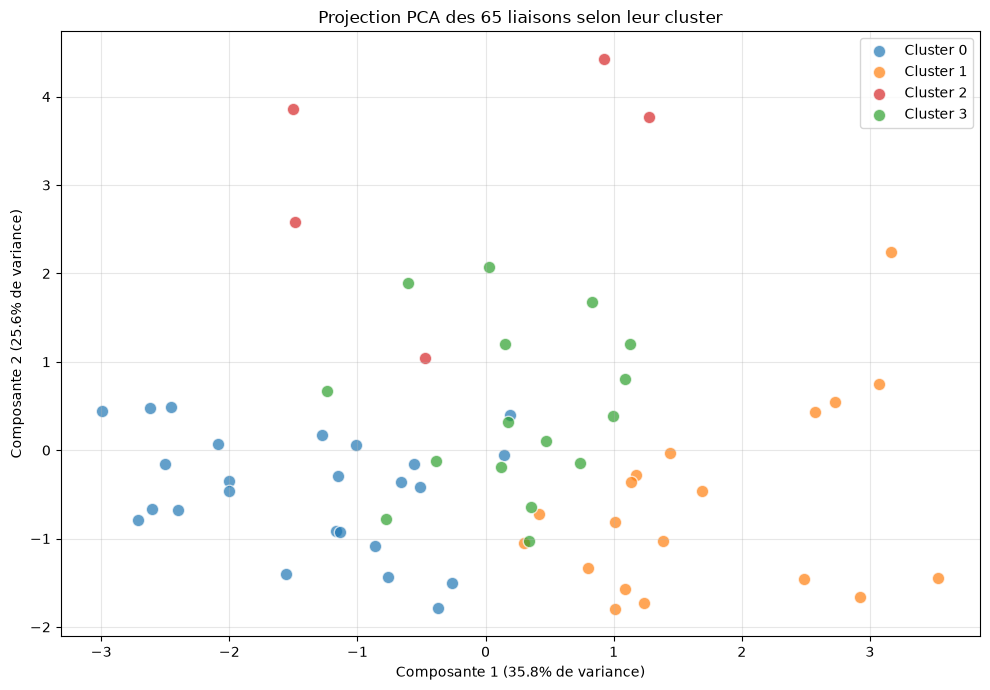

Variance expliquée par les 2 composantes : 61.4%


In [23]:

# On utilise la PCA pour représenter les 7 caractéristiques en 2D
# Cela permet de visualiser la répartition des clusters

from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=SEED)
coords = pca.fit_transform(X)

# On représente chaque paire de gares par un point coloré selon son cluster
fig, ax = plt.subplots(figsize=(10, 7))

couleurs = ["#1f77b4", "#ff7f0e", "#d62728", "#2ca02c"]

for num_cluster in range(4):
    mask = profils["cluster"] == num_cluster
    ax.scatter(coords[mask, 0], coords[mask, 1],
               c=couleurs[num_cluster], label=f"Cluster {num_cluster}",
               s=80, alpha=0.7, edgecolors="white")

ax.set_xlabel(f"Composante 1 ({pca.explained_variance_ratio_[0]*100:.1f}% de variance)")
ax.set_ylabel(f"Composante 2 ({pca.explained_variance_ratio_[1]*100:.1f}% de variance)")
ax.set_title("Projection PCA des 65 liaisons selon leur cluster")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# On affiche la part de variance représentée par les deux composantes
print(f"Variance expliquée par les 2 composantes : {pca.explained_variance_ratio_.sum()*100:.1f}%")


La projection PCA nous permet de représenter les 65 liaisons sur un graphique en deux

In [24]:

# On compare les clusters obtenus avec notre classification géographique
# Pour chaque paire de gares, on récupère son type de liaison

type_par_paire = data.groupby("paire", observed=True)["type_liaison"].first()
profils["type_liaison"] = type_par_paire

# On crée un tableau pour voir comment les types de liaisons
# se répartissent entre les différents clusters
tableau_croise = pd.crosstab(profils["type_liaison"],
                             profils["cluster"],
                             margins=True,
                             margins_name="Total")

print("Répartition des liaisons par type et par cluster :")
tableau_croise


Répartition des liaisons par type et par cluster :


cluster,0,1,2,3,Total
type_liaison,,,,,
international,0,2,4,2,8
radiale depuis Paris,5,8,0,6,19
radiale vers Paris,13,7,0,8,28
transversale,7,2,1,0,10
Total,25,19,5,16,65


## Ce qu'on retient du notebook 04

Dans ce notebook, nous avons utilisé le clustering non supervisé pour regrouper les 65 paires de gares du réseau TGV selon leurs caractéristiques. Nous avons obtenu quatre groupes avec des profils différents, mais aussi des taux de retard allant de 9 % à presque 20 %, alors que le taux de retard n'a pas été utilisé pour former les clusters.

En comparant ces groupes avec notre classification géographique de la section 5 du notebook 02, on remarque qu'ils ne correspondent pas exactement. Certaines catégories géographiques se retrouvent dans plusieurs clusters, tandis que certains clusters regroupent des liaisons de catégories différentes.

On remarque notamment que les liaisons internationales ne se ressemblent pas toutes. Certaines, comme celles vers Barcelone ou la Suisse, se retrouvent avec des liaisons françaises ayant des caractéristiques proches. À l'inverse, les liaisons vers Francfort, l'Italie, Madrid et Stuttgart forment un groupe particulier, avec la liaison Marseille–Tourcoing.

Ce dernier groupe se distingue par des trajets plus longs, un taux de retard nettement plus élevé, proche de 20 %, et une part plus importante de causes liées à la gestion du trafic (environ 28 %, contre 15 à 21 % dans les autres clusters).

Ces résultats montrent que le clustering permet de faire ressortir des différences entre les liaisons que notre classification géographique ne montre pas forcément.

Pour la suite, nous allons voir si ces groupes peuvent aussi être utiles pour prédire les retards. Dans le notebook 05, nous comparerons les performances de modèles de Machine Learning supervisé avec et sans cette information, en complément des variables classiques et des caractéristiques du réseau étudiées dans le notebook 03.